# Health — descriptives (ADM2 panel)

**Question.** Does upstream land-cover change affect health in downstream municipalities?
**Unit.** Municipality (ADM2, 6-digit IBGE `mun_id`) × year (`data/assembly/adm2_panel.parquet`).

As for pollution, this notebook gathers the descriptive evidence needed to choose the
model in [`02_analysis.ipynb`](02_analysis.ipynb). Each section ends with an **→ Informs**
note; §9 collects them into a decision table.

> **Data status.** Health outcomes are **not yet in `adm2_panel`** (deferred in
> `setup/assembly_datasets.yaml`). §0 joins them here via the temporary loaders in
> `src/analysis/panels.py`; once health is wired into assembly, replace §0 with a plain
> `panels.load_adm2_panel()` call.

| § | Topic | Informs |
|---|---|---|
| 0 | Data readiness & join | blockers, key mismatches |
| 1 | Coverage & estimation window | window, municipality sample |
| 2 | Outcomes: definition & distributions | outcome set, rates vs counts, weighting, series breaks |
| 3 | Outcome variance decomposition | FE structure |
| 4 | Land-cover exposure variation | identified classes, FE cost |
| 5 | Local vs upstream exposure, distance | exposure definition, kernel/bandwidth |
| 6 | Controls | control set |
| 7 | Inference structure | cluster level |
| 8 | Raw within-municipality associations | sign/shape priors |
| 9 | Decision table | — |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import descriptives as desc
from src.analysis import panels

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Morbidity channels with a plausible waterborne pathway vs. placebo channels
# that should not respond to upstream water quality.
WATER_CHANNELS = [
    "water_sanitation_gastrointestinal", "leptospirosis_water_exposure",
    "renal_urinary_toxic_water", "toxic_poisoning", "skin_contact",
    "vector_borne_ecological", "perinatal_newborn", "congenital_anomalies",
]
PLACEBO_CHANNELS = ["injuries_accidents_occupational", "violence_self_harm", "mental_health_substance_use"]

# ICD-10 chapters: consistent across the SIH legacy/current switch (see §0), unlike the channels.
ICD_OUTCOMES = {
    "01": "infectious_parasitic",
    "11": "digestive",
    "14": "genitourinary",
    "16": "perinatal",
    "17": "congenital",
    "19": "injury_poisoning",  # placebo-ish: external causes
}

## 0. Data readiness and join

In [3]:
adm2 = panels.load_adm2_panel(years=None)
health_columns = [c for c in adm2.columns if c.startswith(("hosp_", "births", "deaths"))]
print("Health columns in adm2_panel:", health_columns or "NONE — not yet wired into assembly")
print(f"adm2_panel: {len(adm2):,} rows · {adm2.mun_id.nunique():,} municipalities · {adm2.year.min()}–{adm2.year.max()}")

hosp = panels.load_hospitalizations()
channels = panels.load_hospitalizations(breakdown="morbidity_channel").drop(columns="source_system")
icd = (panels.load_hospitalizations(breakdown="icd10_chapter").drop(columns="source_system")
       .rename(columns={f"hosp_icd_{code}": f"hosp_icd_{name}" for code, name in ICD_OUTCOMES.items()}))
births = panels.load_births()

Health columns in adm2_panel: NONE — not yet wired into assembly
adm2_panel: 213,880 rows · 5,347 municipalities · 1985–2024


Key mismatches: health codes absent from the panel (GADM's ADM2 layer predates some municipalities; `000000` is "unknown / abroad").

In [4]:
names = (pd.read_parquet(panels.HEALTH_PROCESSED_DIR / "health_hospitalizations.parquet",
                         columns=["municipality_code", "municipality_name"])
         .drop_duplicates("municipality_code").set_index("municipality_code")["municipality_name"])
panel_ids = set(adm2["mun_id"])
health_ids = set(hosp["mun_id"])
unmatched = sorted(health_ids - panel_ids)
print(f"Health municipalities: {len(health_ids):,}; not in adm2_panel: {len(unmatched)}; "
      f"panel municipalities without health: {len(panel_ids - health_ids)}")
unmatched_hosp = hosp[hosp["mun_id"].isin(unmatched)].groupby("mun_id")["hosp_hospitalizations_count"].sum()
display(pd.DataFrame({"name": names.reindex(unmatched), "hospitalizations_all_years": unmatched_hosp})
        .sort_values("hospitalizations_all_years", ascending=False).head(15))
print(f"Share of all hospitalizations in unmatched codes: "
      f"{unmatched_hosp.sum() / hosp['hosp_hospitalizations_count'].sum():.2%}")

Health municipalities: 5,571; not in adm2_panel: 224; panel municipalities without health: 0


,name,hospitalizations_all_years
211130,SAO LUIS,1.877e+06
000000,Ignorado ou exterior,1.869e+06
330490,SAO GONCALO,1.616e+06
311860,CONTAGEM,8.725e+05
420540,FLORIANOPOLIS,6.27e+05
330330,NITEROI,5.917e+05
351870,GUARUJA,4.546e+05
355280,TABOAO DA SERRA,3.995e+05
150240,CASTANHAL,3.969e+05
354100,PRAIA GRANDE,3.264e+05


Share of all hospitalizations in unmatched codes: 4.36%


In [5]:
df = (adm2
      .merge(hosp, on=["mun_id", "year"], how="left", validate="one_to_one")
      .merge(channels, on=["mun_id", "year"], how="left", validate="one_to_one")
      .merge(icd, on=["mun_id", "year"], how="left", validate="one_to_one")
      .merge(births, on=["mun_id", "year"], how="left", validate="one_to_one"))
df["population"] = df["population"].astype(float)
df["state"] = df["mun_id"].str[:2]
df["state_year"] = df["state"] + "_" + df["year"].astype(str)
df["biome_year"] = df["biome"] + "_" + df["year"].astype(str)

availability = df.groupby("year").agg(
    population=("population", lambda x: x.notna().mean()),
    hospitalizations=("hosp_hospitalizations_count", lambda x: x.notna().mean()),
    births=("births", lambda x: x.notna().mean()),
    source_system=("source_system", "first"),
)
display(availability.T)

year,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
population,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.9888,0.9981,0.9989,0.9981,0.9989,0.9989,0.9989,0.9989,0.9991,0.9991,0.9991,0.9991,0.9991,1,1,1,1,1,1,1,1,1,1,1,1
hospitalizations,0,0,0,0,0,0,0,0,0,0,0.8831,0.8897,0.8917,0.9882,0.9886,0.9888,0.9888,0.9976,0.9981,0.9979,0.9979,0.9985,0.9983,0.9979,0.9991,0.9991,0.9991,0.9991,0.9998,1,1,1,1,1,1,1,1,1,1,1
births,0,0,0,0,0,0,0,0,0,0.789,0.844,0.8657,0.9686,0.9847,0.9877,0.9888,0.9963,0.9981,0.9981,0.9981,0.9983,0.9989,0.9989,0.9989,0.9991,0.9991,0.9991,0.9991,1,1,1,1,1,1,1,1,1,1,0.9998,0
source_system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current


**Births bin check.** The SINASC tables lose the modal (normal) bin in some years —
37–41 weeks in 2003, 2006–07, 2009, 2012, 2016–18 and 3000–3999 g in 2017 — so the bins
do not sum to `Total`. The adverse bins and `Ignorado` are intact, so low-birth-weight
and preterm counts over `Total − Ignorado` are unaffected; this is a health
preprocessing bug to fix upstream.

In [6]:
for name, file_name in [("gestation", "health_gestational_duration"), ("birth weight", "health_birth_weight")]:
    table = pd.read_parquet(panels.HEALTH_PROCESSED_DIR / f"{file_name}.parquet")
    bins = [c for c in table.columns if c not in ("mun_id", "mun_name", "year", "Total")]
    ratio = table.groupby("year").apply(lambda t: t[bins].sum(axis=1).sum() / t["Total"].sum())
    print(f"{name}: years where bins sum to < 99% of Total:", ratio[ratio < 0.99].round(3).to_dict())

gestation: years where bins sum to < 99% of Total: {2003: 0.086, 2006: 0.086, 2007: 0.085, 2009: 0.083, 2012: 0.203, 2016: 0.157, 2017: 0.154, 2018: 0.15}
birth weight: years where bins sum to < 99% of Total: {2017: 0.362}


**SIH series consistency.** National totals in the last legacy-adjacent year vs. a current-system
year. A ratio near 1 means the category is comparable across the 2007/2008 switch. The
morbidity-channel mapping currently returns (near) zero for every channel from 2008 on —
a health preprocessing bug — so the channel outcomes are only usable for 1998–2007 until
fixed; ICD-10 chapters are consistent and serve as the outcome set meanwhile.

In [7]:
CHANNEL_COLUMNS = [c for c in channels.columns if c.startswith("hosp_")]
ICD_COLUMNS = [c for c in icd.columns if c.startswith("hosp_icd_")]
national_totals = df.groupby("year")[CHANNEL_COLUMNS + ICD_COLUMNS].sum()
display(pd.DataFrame({
    "2006": national_totals.loc[2006],
    "2010": national_totals.loc[2010],
    "ratio 2010/2006": national_totals.loc[2010] / national_totals.loc[2006],
}))

,2006,2010,ratio 2010/2006
hosp_cardiovascular_pollution_sensitive,8.823e+05,0,0
hosp_congenital_anomalies,5.556e+04,0,0
hosp_injuries_accidents_occupational,6.602e+05,0,0
hosp_leptospirosis_water_exposure,"2,623",0,0
hosp_mental_health_substance_use,1.643e+05,0,0
hosp_perinatal_newborn,1.976e+05,0,0
hosp_pregnancy_maternal,9.852e+05,0,0
hosp_renal_urinary_toxic_water,4.148e+05,0,0
hosp_respiratory_air_dust,1.395e+06,0,0
hosp_skin_contact,1.447e+05,0,0


**Findings (run of 2026-10-21).** - **Assembly.** Health is not in `adm2_panel`; this notebook joins it temporarily.
- **Unmatched municipalities.** 224 health municipality codes are missing from the
  panel, carrying 4.4% of all hospitalizations. 217 of them are municipalities with no
  upstream river area, which the exposure construction drops (§5), including São Luís,
  São Gonçalo, Niterói and Florianópolis.
- **Morbidity channels.** They are unusable from 2008 on, since every channel is
  (near) zero in current-SIH years. They are erratic even before 2008: toxic poisoning
  is zero in 2001, and the perinatal and congenital levels jump between 2001 and 2002.
  ICD-10 chapters are continuous across the switch and are used instead.
- **Births bins.** The modal SINASC bin is missing in some years; the derived LBW and
  preterm shares are unaffected.

**→ Informs:** blockers before estimation (assembly wiring, morbidity-channel and births preprocessing bugs, missing mortality data) and which unmatched municipalities matter — the large unmatched cities are the headwater/coastal municipalities with no upstream area (§5).

## 1. Coverage and estimation window

In [8]:
# Population (denominator) starts in 2000; SINASC ends in 2023.
ANALYSIS_YEARS = (2000, 2023)
df = df[df["year"].between(*ANALYSIS_YEARS)].reset_index(drop=True)
print(f"Analysis sample: {len(df):,} municipality-years · {df.mun_id.nunique():,} municipalities · "
      f"{ANALYSIS_YEARS[0]}–{ANALYSIS_YEARS[1]}")
display(df.drop_duplicates("mun_id")["biome"].value_counts().rename("municipalities").to_frame().T)
display(df.groupby("year")["population"].sum().rename("population in panel").to_frame().T)

Analysis sample: 128,328 municipality-years · 5,347 municipalities · 2000–2023


biome,Mata Atlântica,Cerrado,Caatinga,Amazônia,Pampa,Pantanal
municipalities,2559,1084,1051,493,151,9


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
population in panel,1.669e+08,1.692e+08,1.755e+08,1.734e+08,1.756e+08,1.775e+08,1.794e+08,1.813e+08,1.832e+08,1.851e+08,1.869e+08,1.901e+08,1.901e+08,1.917e+08,1.933e+08,1.95e+08,1.966e+08,1.982e+08,1.998e+08,2.013e+08,2.029e+08,2.044e+08,2.02e+08,2.028e+08


**Findings (run of 2026-10-21).** Population starts in 2000 and SINASC ends in 2023, so the window is 2000–2023: 128,328
municipality-years across 5,347 municipalities. Within it, population, hospitalization
and births coverage is above 99%.

**→ Informs:** estimation window and whether the unmatched / missing-population municipalities need handling.

## 2. Outcomes: definition and distributions

In [9]:
PER = 1_000
rates = pd.DataFrame(index=df.index)
rates["hosp_rate"] = df["hosp_hospitalizations_count"] / df["population"] * PER
rates["hosp_death_rate"] = df["hosp_in_hospital_deaths_count"] / df["population"] * PER
for name in ICD_OUTCOMES.values():
    rates[f"rate_icd_{name}"] = df[f"hosp_icd_{name}"] / df["population"] * PER
# Morbidity channels are kept for 1998-2007 only, where the mapping works (§0).
legacy = df["source_system"].eq("legacy")
for channel in WATER_CHANNELS + PLACEBO_CHANNELS:
    rates[f"rate_{channel}"] = (df[f"hosp_{channel}"] / df["population"] * PER).where(legacy)
rates["births_rate"] = df["births"] / df["population"] * PER
rates["low_birth_weight_share"] = df["births_low_weight"] / df["births_weight_known"]
rates["preterm_share"] = df["births_preterm"] / df["births_gestation_known"]
RATE_COLUMNS = rates.columns.tolist()
df = df.join(rates)

display(desc.distribution_table(df, RATE_COLUMNS))
display(df[[c for c in df.columns if c.startswith("hosp_icd_")]].isna().mean()
        .rename("share missing").to_frame().T)

,n,share_zero,share_negative,n_distinct,modal_value,modal_share,min,p01,median,p99,p999,max,skew,skew_log_positive
hosp_rate,1.281e+05,0,0,1.238e+05,58.82,0.0001639,0.1757,16.13,62.64,142.5,209.5,"3,077",12.34,-1.388
hosp_death_rate,1.281e+05,0.01138,0,9.747e+04,0,0.01138,0,0,1.931,6.13,8.339,169,14.03,-0.9983
rate_icd_infectious_parasitic,1.282e+05,0.003432,0,1.1e+05,0,0.003432,0,0.3913,4.183,31.81,61.29,167.4,3.835,-0.08254
rate_icd_digestive,1.282e+05,0.001342,0,1.097e+05,0,0.001342,0,0.8743,5.564,17.1,28.28,340,8.901,-0.8336
rate_icd_genitourinary,1.282e+05,0.002457,0,1.072e+05,0,0.002457,0,0.5153,4.112,15.56,25.17,249.5,5.869,-0.6277
rate_icd_perinatal,1.282e+05,0.05928,0,8.489e+04,0,0.05928,0,0,0.7958,4.594,11.75,64.67,9.96,-0.3463
rate_icd_congenital,1.282e+05,0.1417,0,6.926e+04,0,0.1417,0,0,0.311,1.603,3.406,22.04,6.718,-0.2154
rate_icd_injury_poisoning,1.282e+05,0.002286,0,1.08e+05,0,0.002286,0,0.5619,4.625,13.85,20.23,324.9,11.65,-1.011
rate_water_sanitation_gastrointestinal,4.259e+04,0.02432,0,3.887e+04,0,0.02432,0,0,3.052,25.24,43.76,111.4,2.934,-0.5078
rate_leptospirosis_water_exposure,4.259e+04,0.8892,0,"4,647",0,0.8892,0,0,0,0.2805,1.106,5.5,25.64,0.1447


,hosp_icd_infectious_parasitic,hosp_icd_02,hosp_icd_03,hosp_icd_04,hosp_icd_05,hosp_icd_06,hosp_icd_07,hosp_icd_08,hosp_icd_09,hosp_icd_10,hosp_icd_digestive,hosp_icd_12,hosp_icd_13,hosp_icd_genitourinary,hosp_icd_15,hosp_icd_perinatal,hosp_icd_congenital,hosp_icd_18,hosp_icd_injury_poisoning,hosp_icd_20,hosp_icd_21,hosp_icd_99
share missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Small-number noise: dispersion of each rate by population decile. Strongly falling dispersion with size argues for population weights or a count model (PPML with population exposure) over OLS on rates.

In [10]:
decile = pd.qcut(df["population"], 10, labels=[f"D{i}" for i in range(1, 11)])
dispersion = (df.groupby(decile, observed=True)[RATE_COLUMNS].std()
              / df.groupby(decile, observed=True)[RATE_COLUMNS].mean())
display(dispersion.T.round(2))

population,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
hosp_rate,0.42,0.6,0.42,0.42,0.42,0.42,0.39,0.35,0.33,0.28
hosp_death_rate,0.69,0.94,0.64,0.63,0.63,0.63,0.62,0.59,0.57,0.42
rate_icd_infectious_parasitic,1.11,1.2,1.16,1.09,1.07,1.1,1.01,0.85,0.87,0.83
rate_icd_digestive,0.58,0.77,0.56,0.61,0.57,0.58,0.54,0.54,0.47,0.37
rate_icd_genitourinary,0.71,0.9,0.71,0.69,0.69,0.67,0.63,0.56,0.52,0.44
rate_icd_perinatal,1.38,1.14,1.25,1.03,1.22,1.13,1.14,1.02,0.89,0.68
rate_icd_congenital,1.37,1.17,1.02,0.99,1.06,0.87,0.98,0.95,0.63,0.51
rate_icd_injury_poisoning,0.62,0.79,0.57,0.56,0.54,0.55,0.54,0.52,0.5,0.4
rate_water_sanitation_gastrointestinal,1.36,1.33,1.29,1.19,1.08,1.06,1,0.89,0.94,1.16
rate_leptospirosis_water_exposure,8.62,8.04,6.8,6.38,8.8,4.41,5.08,5.46,6.42,2.91


National (population-weighted) time series. The dashed line marks the SIH legacy → current switch (2007/2008); a level shift is absorbed by year FE, a differential one is not.

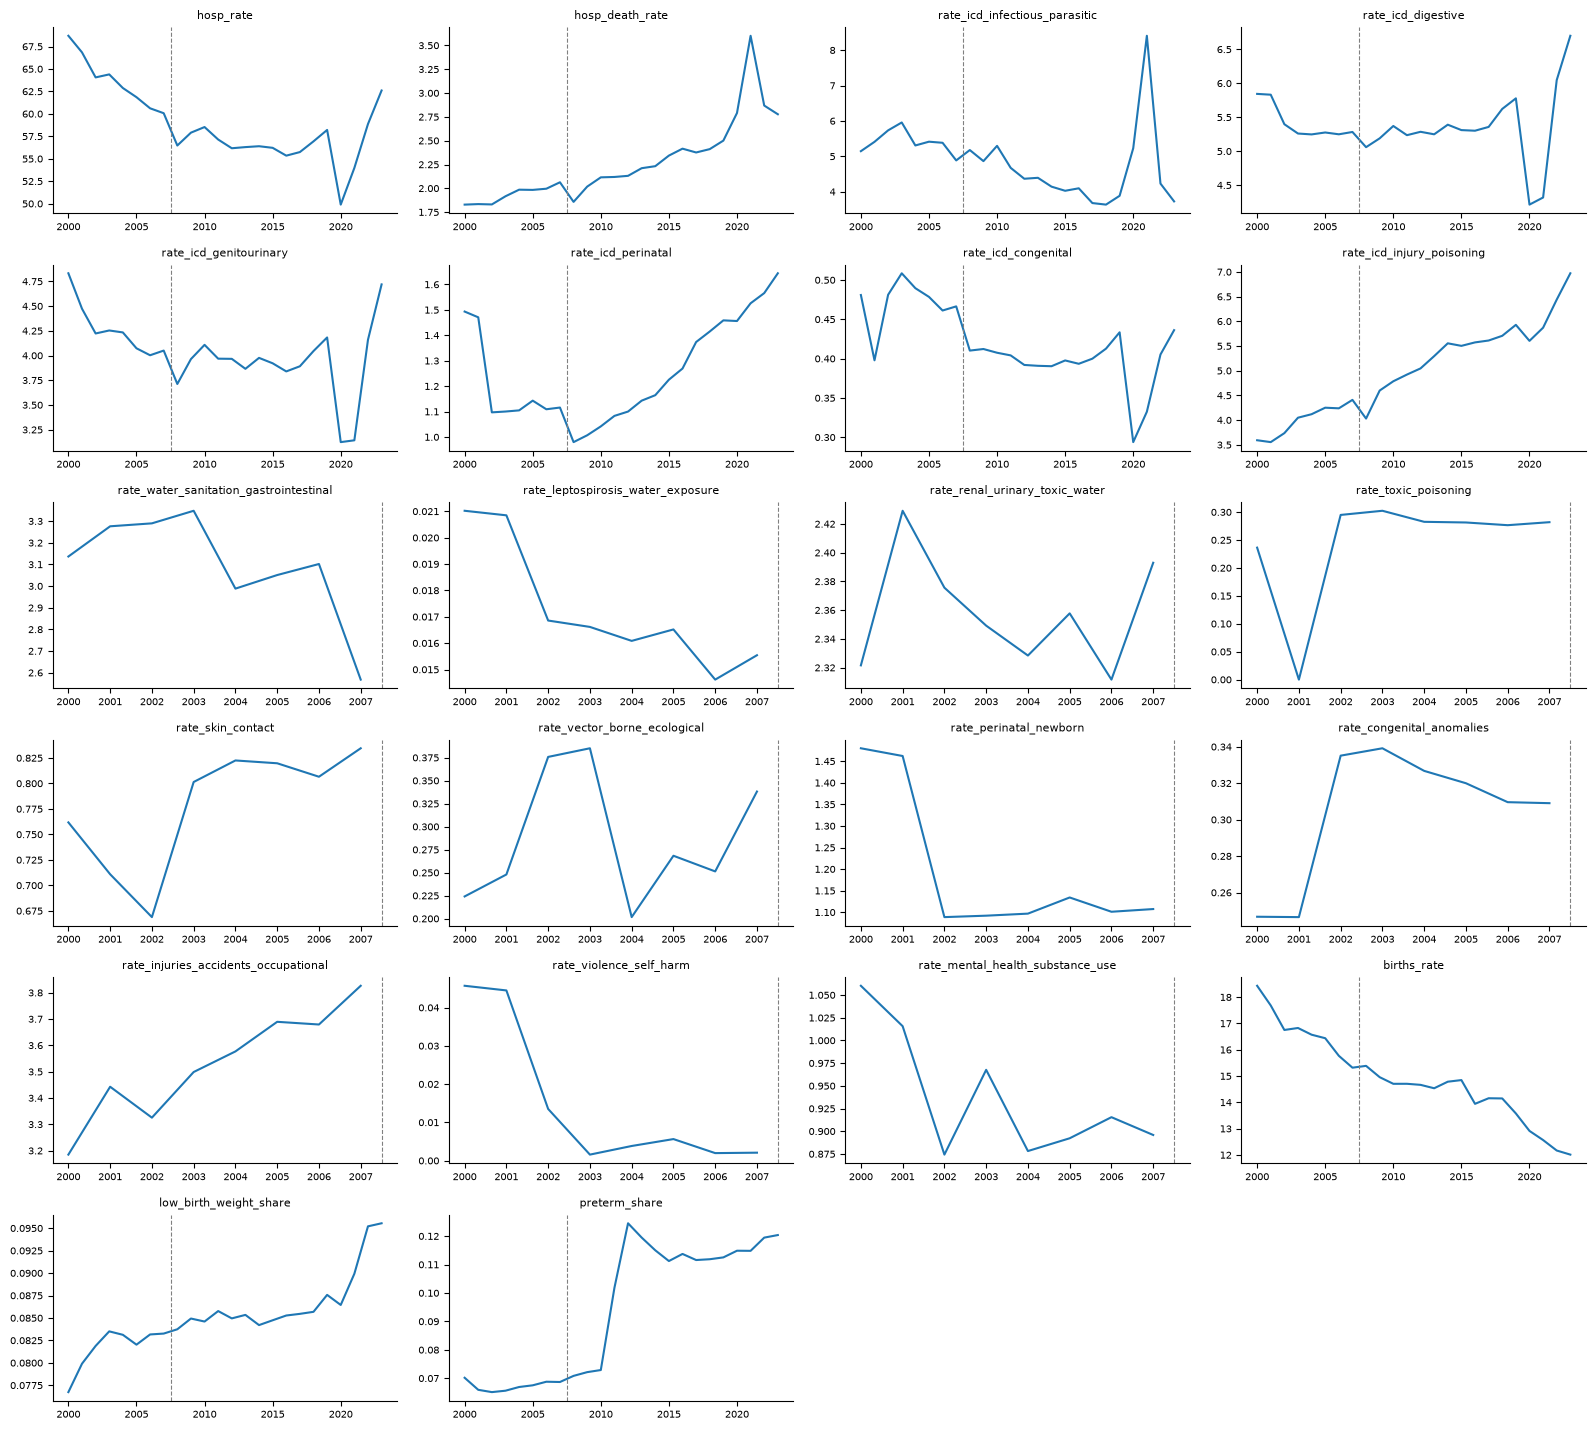

In [11]:
def population_weighted_mean(values, weights):
    observed = values.notna() & weights.notna()
    return np.average(values[observed], weights=weights[observed]) if observed.any() else np.nan

national = df.groupby("year").apply(
    lambda d: pd.Series({c: population_weighted_mean(d[c], d["population"]) for c in RATE_COLUMNS})
)
n_cols = 4
n_rows = int(np.ceil(len(RATE_COLUMNS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 2.4 * n_rows))
for ax, column in zip(axes.flat, RATE_COLUMNS):
    national[column].plot(ax=ax)
    ax.axvline(2007.5, ls="--", color="grey", lw=0.8)
    ax.set_title(column, fontsize=8); ax.tick_params(labelsize=7); ax.set_xlabel("")
for ax in axes.flat[len(RATE_COLUMNS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-21).** - **Zeros and noise.** ICD-chapter rates have few zeros, except congenital (14%) and
  perinatal (6%). Their coefficient of variation falls steadily with population (e.g.
  LBW share: 0.79 in the smallest decile vs 0.17 in the largest). That argues for
  population weights or PPML with population as exposure.
- **National series.** All-cause hospitalization falls from 69 to 55 per 1,000 between
  2000 and 2019, with a small step at the 2008 SIH switch. Hospitalizations dip in
  2020–21 (COVID), and the infectious chapter spikes in 2021, so 2020–21 need care
  (year FE, or exclusion as robustness).
- **Preterm break.** The preterm share jumps from about 7% to 12% in 2010–12, in line
  with the 2011 SINASC form change in how gestational age is recorded. It is a
  measurement break, so preterm should be used only within 2012–2023 or with care.
  LBW is smooth.

**→ Informs:** outcome set (water-related channels vs placebo channels), rates vs. counts
(OLS on log rates vs. PPML), population weights, zero handling for small channels, and
treatment of the 2007/2008 SIH break (year FE, source-system interaction, or post-2008
only).

## 3. Outcome variance decomposition

In [12]:
log_rates = np.log(df[RATE_COLUMNS].where(df[RATE_COLUMNS] > 0))
log_rates[["mun_id", "year", "state_year", "biome_year"]] = df[["mun_id", "year", "state_year", "biome_year"]]
OUTCOME_FE_SETS = {
    "mun": ["mun_id"],
    "mun + year": ["mun_id", "year"],
    "mun + biome×year": ["mun_id", "biome_year"],
    "mun + state×year": ["mun_id", "state_year"],
}
display(desc.variation_table(log_rates, RATE_COLUMNS, OUTCOME_FE_SETS).filter(like="share:"))

,share: mun,share: mun + year,share: mun + biome×year,share: mun + state×year
hosp_rate,0.4027,0.3809,0.3706,0.3386
hosp_death_rate,0.4203,0.2701,0.2636,0.2446
rate_icd_infectious_parasitic,0.482,0.4312,0.4106,0.3786
rate_icd_digestive,0.4879,0.4477,0.4431,0.4148
rate_icd_genitourinary,0.5129,0.4894,0.4782,0.4465
rate_icd_perinatal,0.6465,0.5683,0.559,0.5159
rate_icd_congenital,0.6505,0.6326,0.6255,0.5993
rate_icd_injury_poisoning,0.5913,0.3864,0.3813,0.3347
rate_water_sanitation_gastrointestinal,0.2822,0.2749,0.2726,0.2566
rate_leptospirosis_water_exposure,0.121,0.1193,0.1163,0.1066


**Findings (run of 2026-10-21).** Municipality FE leave 40–65% of the variance in log ICD-chapter rates, and adding
state×year FE removes another 5–15 pp. In-hospital deaths and the injury chapter
respond most to year effects (secular trends). LBW keeps 76% of its variance after all
FE, most of it small-municipality noise (see the dispersion table).

**→ Informs:** FE structure (year vs. biome×year vs. state×year) and how much outcome variation is left to explain.

## 4. Land-cover exposure: levels and identifying variation

In [13]:
LC = panels.LAND_COVER_SHARE_COLUMNS
ALR = panels.LAND_COVER_ALR_COLUMNS
display(df[LC + ALR].describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]).T)
EXPOSURE_FE_SETS = {
    "mun": ["mun_id"],
    "mun + year": ["mun_id", "year"],
    "mun + state×year": ["mun_id", "state_year"],
}
display(desc.variation_table(df, LC + ALR, EXPOSURE_FE_SETS))

,count,mean,std,min,1%,10%,50%,90%,99%,max
lc_forest,1.283e+05,0.4234,0.2531,0,0.04593,0.1263,0.3789,0.8087,0.978,1
lc_nonforest_nat,1.283e+05,0.04329,0.1,0,0,1.772e-05,0.009332,0.116,0.5604,0.9566
lc_pasture,1.283e+05,0.2656,0.2058,0,0,0.02214,0.2312,0.5608,0.7919,1
lc_agriculture,1.283e+05,0.1184,0.178,0,0,6.245e-05,0.02926,0.3684,0.7519,0.913
lc_farming_unclassified,1.283e+05,0.127,0.1046,0,0,0.00827,0.1077,0.2647,0.4137,0.8789
lc_urban,1.283e+05,0.01305,0.03647,0,0,0.0002767,0.004491,0.02834,0.1512,0.9996
lc_mining,1.283e+05,0.000566,0.004416,0,0,0,0,0.0005849,0.01184,0.2107
lc_other,1.283e+05,0.001209,0.00299,0,0,1.801e-05,0.0006144,0.00265,0.008901,0.1295
lc_water,1.283e+05,0.007383,0.01541,0,0,0.0001998,0.002445,0.01971,0.07857,0.3983
alr_pasture,1.283e+05,-0.9763,1.955,-9.21,-8.789,-3.178,-0.6493,1.036,2.19,9.21


,n,sd_total,sd: mun,share: mun,sd: mun + year,share: mun + year,sd: mun + state×year,share: mun + state×year
lc_forest,1.283e+05,0.2531,0.02262,0.007986,0.02104,0.006914,0.0162,0.004096
lc_nonforest_nat,1.283e+05,0.1,0.01148,0.01318,0.01114,0.0124,0.008829,0.007792
lc_pasture,1.283e+05,0.2058,0.04051,0.03874,0.03845,0.0349,0.02855,0.01924
lc_agriculture,1.283e+05,0.178,0.02873,0.02606,0.02486,0.01952,0.02153,0.01464
lc_farming_unclassified,1.283e+05,0.1046,0.0229,0.0479,0.02139,0.04177,0.01924,0.0338
lc_urban,1.283e+05,0.03647,0.003752,0.01058,0.003343,0.008401,0.003168,0.007543
lc_mining,1.283e+05,0.004416,0.0009611,0.04737,0.0009499,0.04627,0.0009287,0.04423
lc_other,1.283e+05,0.00299,0.0007753,0.06725,0.0007739,0.06701,0.0007594,0.06452
lc_water,1.283e+05,0.01541,0.002375,0.02377,0.002347,0.02321,0.002228,0.02092
alr_pasture,1.283e+05,1.955,0.2581,0.01744,0.2555,0.01708,0.1973,0.01019


In [14]:
first_obs = df[df["year"] == ANALYSIS_YEARS[0]].set_index("mun_id")[LC]
last_obs = df[df["year"] == ANALYSIS_YEARS[1]].set_index("mun_id")[LC]
long_diff = (last_obs - first_obs).dropna()
summary = long_diff.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
for threshold in (0.01, 0.05):
    summary[f"share |Δ| > {threshold:.0%}"] = (long_diff.abs() > threshold).mean()
print(f"Long difference {ANALYSIS_YEARS[0]}→{ANALYSIS_YEARS[1]}, {len(long_diff):,} municipalities")
display(summary)
display(long_diff.groupby(df.drop_duplicates("mun_id").set_index("mun_id")["biome"]).mean())

Long difference 2000→2023, 5,347 municipalities


,count,mean,std,min,5%,25%,50%,75%,95%,max,share |Δ| > 1%,share |Δ| > 5%
lc_forest,"5,347",-0.03227,0.0675,-0.6008,-0.1692,-0.05514,-0.01162,0.007951,0.03446,0.1916,0.7339,0.2947
lc_nonforest_nat,"5,347",-0.009278,0.03531,-0.4306,-0.05253,-0.003297,-0.0001572,5.095e-05,0.002513,0.105,0.1472,0.0533
lc_pasture,"5,347",-0.03897,0.1148,-0.6483,-0.2488,-0.08765,-0.02004,0.02337,0.1216,0.5982,0.8609,0.5244
lc_agriculture,"5,347",0.0409,0.06986,-0.7,-0.0166,0.0004729,0.01416,0.06329,0.1732,0.835,0.6061,0.3105
lc_farming_unclassified,"5,347",0.03287,0.05735,-0.374,-0.0368,0.0001313,0.0234,0.0573,0.1265,0.5,0.7771,0.3256
lc_urban,"5,347",0.005535,0.01072,-0.006074,0,0.0008897,0.002592,0.005392,0.02089,0.2,0.1313,0.01178
lc_mining,"5,347",0.0005271,0.003444,-2.278e-06,0,0,0,7.622e-05,0.001829,0.1428,0.01197,0.0007481
lc_other,"5,347",3.872e-05,0.002037,-0.03892,-0.001374,-0.0001441,5.457e-05,0.0003741,0.001234,0.06818,0.004114,0.000187
lc_water,"5,347",0.0006436,0.003416,-0.08676,-0.001094,-8.422e-05,0.0002188,0.0009814,0.00489,0.0575,0.0144,0.0007481


,lc_forest,lc_nonforest_nat,lc_pasture,lc_agriculture,lc_farming_unclassified,lc_urban,lc_mining,lc_other,lc_water
biome,,,,,,,,,
Amazônia,-0.1181,-0.002511,0.08188,0.03261,0.003784,0.001535,0.001286,-0.0007226,0.0002572
Caatinga,-0.03862,0.0003619,0.01005,0.01582,0.006699,0.004844,5.521e-05,0.0001932,0.0005994
Cerrado,-0.05641,-0.004899,-0.05214,0.06774,0.04019,0.004166,0.0006278,-0.0002773,0.0009968
Mata Atlântica,-0.005237,-0.009217,-0.07896,0.03933,0.0453,0.007317,0.000554,0.0002618,0.0006539
Pampa,0.008146,-0.1319,-0.005428,0.07749,0.04769,0.003318,0.0001585,-4.212e-05,0.0005964
Pantanal,-0.04377,0.007371,0.01189,0.02579,0.01544,0.0007872,0.000522,-0.0003007,-0.01772


In [15]:
alr_within = desc.demean(df, ALR, ["mun_id", "state_year"])
corr = alr_within.corr()
display(corr.round(2))
display(pd.Series(np.diag(np.linalg.inv(corr.to_numpy())), index=ALR, name="VIF (within)").to_frame().T)

,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
alr_pasture,1,0.06,0.21,0.26,0.23,0.15
alr_agriculture,0.06,1,0.11,0.13,0.11,0.05
alr_farming_unclassified,0.21,0.11,1,0.16,0.13,0.08
alr_urban,0.26,0.13,0.16,1,0.26,0.17
alr_mining,0.23,0.11,0.13,0.26,1,0.09
alr_other,0.15,0.05,0.08,0.17,0.09,1


,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
VIF (within),1.142,1.032,1.072,1.161,1.116,1.045


**Findings (run of 2026-10-21).** - **Identifying variation.** As on the sensor side, very little exposure variation
  survives the FE: 0.4–2% of the share variance after municipality + state×year FE.
- **Long differences.** They are large, though: 52% of municipalities saw upstream
  pasture move by more than 5 pp between 2000 and 2023.
- **Biome patterns.** The Amazon shows forest-to-pasture conversion (−12 pp forest,
  +8 pp pasture on average). Cerrado and Mata Atlântica show pasture-to-agriculture
  conversion (pasture −5 to −8 pp, agriculture +4 to +7 pp). The same regressor
  therefore captures different transitions by biome.
- **Collinearity.** Within-FE ALR correlations are at most 0.26.

**→ Informs:** which classes are estimable, FE cost in identifying variation, and heterogeneity by biome.

## 5. Local vs. upstream exposure and distance weighting

The ADM2 composition in `adm2_panel` is built from 25 km rings along the river network
(`src/data/shared/adm2_upstream_buckets.py`). Negative buckets are the bodies of the
ADM2-touching trenches (the municipality's **local** catchment, flagged
`bucket_intersects_adm2`); buckets ≥ 0 are **strictly upstream**. The assembled exposure:

- **keeps only buckets 0–500** (inner join on `LAND_COVER_COMPOSITION_BUCKET_MAP`), so
  `lc_*`/`alr_*` are purely upstream and local land use is not in the panel at all;
- therefore **drops municipalities with no upstream area** (only local buckets) instead
  of giving them zero upstream exposure;
- uses a **Gaussian kernel with bandwidth 1,000,000** (`DEFAULT_ADM2_KERNEL_BANDWIDTH_KM`),
  i.e. effectively uniform weights over 0–500 km+.

For health, separating *local* land use (which also acts through air quality, income,
occupation) from *upstream* land use (the water channel) is central to identification,
so the local block needs to come back into assembly as its own regressor set.

In [16]:
from src.data.shared.sensor_upstream import DEFAULT_ADM2_KERNEL_BANDWIDTH_KM, bucket_kernel_weights
from src.data.sources.land_cover.constants import LAND_COVER_COMPOSITION_BUCKET_MAP

midpoints = {b: m for b, (_label, m) in LAND_COVER_COMPOSITION_BUCKET_MAP.items()}
kernel_weights = pd.DataFrame({
    "gaussian (assembly)": bucket_kernel_weights(list(midpoints.values()), kernel="gaussian",
                                                 bandwidth=DEFAULT_ADM2_KERNEL_BANDWIDTH_KM),
    "gaussian, bw=100": bucket_kernel_weights(list(midpoints.values()), kernel="gaussian", bandwidth=100),
    "inv_sqrt (sensor)": bucket_kernel_weights(list(midpoints.values()), kernel="inv_sqrt_distance"),
}, index=list(midpoints))
display((kernel_weights / kernel_weights.max()).T.round(3))

,0,25,50,75,100,125,150,175,200,225,250,275,300,325,350,375,400,425,450,475,500
gaussian (assembly),1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
"gaussian, bw=100",1,0.882,0.687,0.472,0.287,0.153,0.072,0.03,0.011,0.004,0.001,0,0,0,0,0,0,0,0,0,0
inv_sqrt (sensor),1,0.577,0.447,0.378,0.333,0.302,0.277,0.258,0.243,0.229,0.218,0.209,0.2,0.192,0.186,0.18,0.174,0.169,0.164,0.16,0.129


In [17]:
LC_ADM2_BUCKETED_PATH = PROJECT_ROOT / "data/land_cover/processed/aggregate/land_cover_adm2_upstream.parquet"
SNAPSHOT_YEARS = list(ANALYSIS_YEARS)
CLASS_LABELS = {1: "forest", 30: "pasture", 31: "agriculture", 41: "mining"}
adm2_buckets = pd.read_parquet(
    LC_ADM2_BUCKETED_PATH,
    filters=[("land_cover_class", "in", list(CLASS_LABELS)), ("year", "in", SNAPSHOT_YEARS)],
)
adm2_buckets["class"] = adm2_buckets["land_cover_class"].map(CLASS_LABELS)
adm2_buckets["segment"] = np.where(adm2_buckets["bucket"] < 0, "local", "upstream")

display(pd.crosstab(adm2_buckets["segment"], adm2_buckets["bucket_intersects_adm2"]))
areas = adm2_buckets[adm2_buckets["year"] == SNAPSHOT_YEARS[0]].drop_duplicates(["mun_id", "bucket"])
display(areas.groupby("segment")["n"].sum().div(areas["n"].sum()).rename("share of total bucket size").to_frame().T)

has_upstream = areas.groupby("mun_id")["bucket"].max() >= 0
print(f"Municipalities in land-cover buckets: {len(has_upstream):,}; with no upstream area "
      f"(dropped from adm2_panel): {(~has_upstream).sum():,}; of these in panel: "
      f"{has_upstream[~has_upstream].index.isin(adm2['mun_id']).sum()}")

bucket_intersects_adm2,False,True
segment,,
local,1440,56976
upstream,356720,0


segment,local,upstream
share of total bucket size,0.03425,0.9657


Municipalities in land-cover buckets: 5,564; with no upstream area (dropped from adm2_panel): 217; of these in panel: 0


Do local and upstream land-cover change move together? If highly correlated, the two channels cannot be separated.

In [18]:
adm2_buckets["cnt"] = adm2_buckets["share"] * adm2_buckets["n"]
segment_size = (adm2_buckets.drop_duplicates(["mun_id", "year", "bucket"])
                .groupby(["mun_id", "year", "segment"])["n"].sum())
segment_class = adm2_buckets.groupby(["mun_id", "year", "segment", "class"])["cnt"].sum()
segment_share = segment_class.div(segment_size).unstack(["segment", "class"])
change = segment_share.xs(SNAPSHOT_YEARS[1], level="year") - segment_share.xs(SNAPSHOT_YEARS[0], level="year")
level = segment_share.xs(SNAPSHOT_YEARS[0], level="year")
rows = {}
for land_cover_class in CLASS_LABELS.values():
    pair = change[[("local", land_cover_class), ("upstream", land_cover_class)]].dropna()
    rows[land_cover_class] = {
        "n_municipalities": len(pair),
        "corr(level local, level upstream)": level[[("local", land_cover_class), ("upstream", land_cover_class)]].corr().iloc[0, 1],
        "corr(Δlocal, Δupstream)": pair.corr().iloc[0, 1],
        "sd Δlocal": pair.iloc[:, 0].std(),
        "sd Δupstream": pair.iloc[:, 1].std(),
    }
display(pd.DataFrame(rows).T)

,n_municipalities,"corr(level local, level upstream)","corr(Δlocal, Δupstream)",sd Δlocal,sd Δupstream
forest,"5,347",0.869,0.7612,0.06944,0.06527
pasture,"5,347",0.8113,0.8284,0.1264,0.1125
agriculture,"5,347",0.8105,0.7305,0.08062,0.06918
mining,"5,347",0.3144,0.315,0.002225,0.003189


**Findings (run of 2026-10-21).** - **What the exposure covers.** Local (municipality-touching) catchment area is only 3%
  of total bucket size. The panel's exposure is therefore almost entirely upstream land,
  and the assembled kernel weights every ring equally.
- **Local vs upstream changes.** They are highly correlated (forest 0.76, pasture 0.83,
  agriculture 0.73; mining 0.32). Without the local block, any upstream coefficient
  also picks up local land-use change, which acts on health through non-water channels
  (income, fires, occupation).

**→ Informs:** the exposure definition (separate local and upstream regressors; zero
upstream exposure for headwater municipalities instead of dropping them), the kernel
and bandwidth (the assembly default is effectively flat), and the upstream reach.

## 6. Controls

In [19]:
CLIMATE = panels.CLIMATE_VARIABLES
display(df[CLIMATE + ["population"]].describe().T)
climate_within = desc.demean(df, CLIMATE, ["mun_id", "state_year"])
display(climate_within.corr().round(2))

,count,mean,std,min,25%,50%,75%,max
2t,1.283e+05,22.38,3.197,13.3,19.62,22.72,25.1,29.46
2d,1.283e+05,16.59,2.438,10.42,14.8,16.12,18.07,24.18
tp,1.283e+05,3.633,1.516,0.212,2.469,3.707,4.629,10.65
sro,1.283e+05,0.297,0.2608,0.0006087,0.1176,0.2605,0.3954,3.39
ssro,1.283e+05,0.7653,0.768,0,0.05546,0.5647,1.259,5.738
pev,1.283e+05,-8.637,3.051,-32.92,-9.528,-7.995,-6.683,-3.823
swvl1,1.283e+05,0.3265,0.0913,0.06294,0.2592,0.3431,0.4041,0.4843
swvl2,1.283e+05,0.34,0.08247,0.06107,0.279,0.3516,0.4087,0.4974
2t_daily_min,1.283e+05,10.4,7.047,-5.276,5.126,10.62,16.69,23.59
2t_daily_max,1.283e+05,34.42,2.466,24.4,32.64,34.61,36.31,42.12


,2t,2d,tp,sro,ssro,pev,swvl1,swvl2,2t_daily_min,2t_daily_max
2t,1,-0.65,-0.41,-0.18,-0.12,-0.57,-0.66,-0.63,0.12,0.37
2d,-0.65,1,0.37,0.13,0.01,0.53,0.65,0.6,0.02,-0.34
tp,-0.41,0.37,1,0.76,0.72,0.38,0.5,0.52,0.02,-0.21
sro,-0.18,0.13,0.76,1,0.53,0.18,0.22,0.25,0.02,-0.11
ssro,-0.12,0.01,0.72,0.53,1,0.14,0.07,0.07,0.02,-0.1
pev,-0.57,0.53,0.38,0.18,0.14,1,0.52,0.5,-0.04,-0.24
swvl1,-0.66,0.65,0.5,0.22,0.07,0.52,1,0.95,-0.04,-0.3
swvl2,-0.63,0.6,0.52,0.25,0.07,0.5,0.95,1,-0.04,-0.29
2t_daily_min,0.12,0.02,0.02,0.02,0.02,-0.04,-0.04,-0.04,1,0.01
2t_daily_max,0.37,-0.34,-0.21,-0.11,-0.1,-0.24,-0.3,-0.29,0.01,1


**Findings (run of 2026-10-21).** Upstream annual precipitation, runoff and sub-surface runoff are strongly correlated
within municipality (0.72–0.76), and so are the two soil-moisture layers (0.95). A
parsimonious set (temperature, precipitation, one soil-moisture layer) loses little.

The ADM2 climate block is *upstream* climate (same buckets/kernel as land cover). For
health, local climate (heat, rainfall at the municipality) is a direct confounder and is
not in the panel.

**→ Informs:** climate control set, whether local climate must be added to assembly, and
whether population enters as control, weight or exposure.

## 7. Inference structure

In [20]:
municipalities = df.drop_duplicates("mun_id")
per_state = municipalities.groupby("state").size()
print(f"States: {len(per_state)}; effective number (inverse HHI): {desc.effective_cluster_count(per_state):.1f}")
display(per_state.describe().rename("municipalities per state").to_frame().T)
display(df.groupby("biome_year")["mun_id"].nunique().describe().rename("municipalities per biome×year").to_frame().T)
print("River-system id in adm2_panel:", "system_id" in df.columns)

States: 27; effective number (inverse HHI): 14.0


,count,mean,std,min,25%,50%,75%,max
municipalities per state,27,198,194.6,1,74,141,230.5,827


,count,mean,std,min,25%,50%,75%,max
municipalities per biome×year,144,891.2,852.4,9,151,772,"1,084","2,559"


River-system id in adm2_panel: False


**Findings (run of 2026-10-21).** There are 27 states, effective about 14, so state clustering is a few-cluster problem.
Otto-3 basins, as on the sensor side, would also capture correlation along rivers.

Upstream exposure is shared by municipalities on the same river, so errors are
correlated along river systems, not just within states. `adm2_panel` carries no
river-system id; adding the municipality's dominant `system_id` to assembly would allow
clustering on it.

**→ Informs:** cluster level (municipality, state, river system, or spatial HAC).

## 8. Raw within-municipality associations

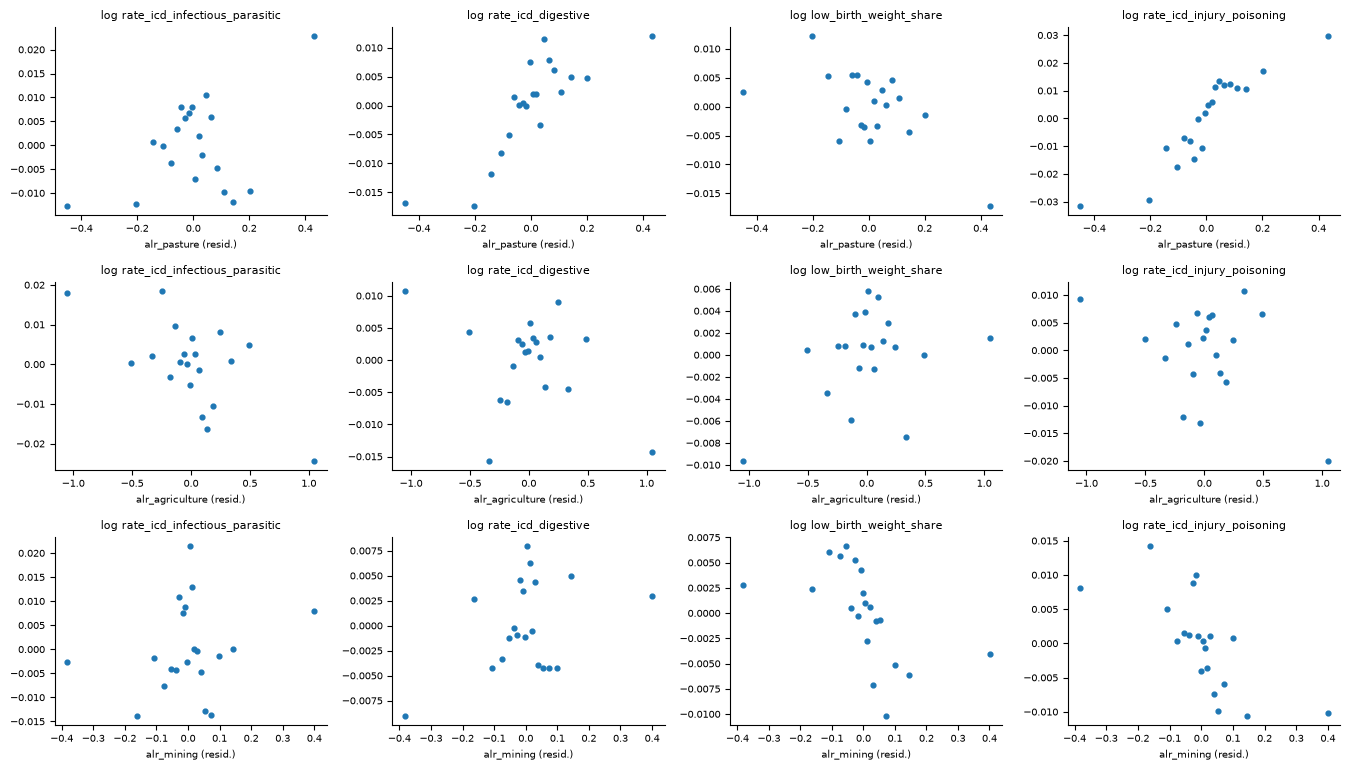

In [21]:
KEY_OUTCOMES = ["rate_icd_infectious_parasitic", "rate_icd_digestive", "low_birth_weight_share",
                "rate_icd_injury_poisoning"]
KEY_REGRESSORS = ["alr_pasture", "alr_agriculture", "alr_mining"]
frame = log_rates[["mun_id", "state_year"]].join(log_rates[KEY_OUTCOMES]).join(df[KEY_REGRESSORS])
fig, axes = plt.subplots(len(KEY_REGRESSORS), len(KEY_OUTCOMES),
                         figsize=(3.4 * len(KEY_OUTCOMES), 2.6 * len(KEY_REGRESSORS)), squeeze=False)
for i, regressor in enumerate(KEY_REGRESSORS):
    for j, outcome in enumerate(KEY_OUTCOMES):
        residuals = desc.demean(frame, [outcome, regressor], ["mun_id", "state_year"])
        bins = desc.binscatter(residuals[regressor], residuals[outcome])
        axes[i, j].scatter(bins["x"], bins["y"], s=12)
        axes[i, j].set_title(f"log {outcome}", fontsize=8)
        axes[i, j].set_xlabel(f"{regressor} (resid.)", fontsize=7)
        axes[i, j].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-21).** **The placebo fails.** Injury/poisoning hospitalizations rise steeply and monotonically
with upstream pasture after FE, as do digestive hospitalizations. Infectious/parasitic
and LBW show no clear pattern. A pasture association that is as strong for injuries as
for digestive disease points to confounding by local economic change (or by access to
hospital care), not a water channel. The health design needs the local land-use block
and a utilization control (e.g. the all-cause rate) before any causal reading.

Binned scatter after municipality + state×year FE; injury/poisoning is a rough placebo. **→ Informs:** sign/shape priors and functional form.

## 9. Decision table

| Parameter | Evidence | Decision |
|---|---|---|
| Estimation window | §0, §1 | |
| Municipality sample (unmatched codes, missing pop.) | §0, §1 | |
| Outcome set (ICD chapters / fixed channels, births, placebo) | §0, §2 | |
| Estimator (OLS log rate vs. PPML counts w/ exposure) | §2 | |
| Population weighting | §2 | |
| SIH 2007/2008 break handling | §2 | |
| Fixed effects | §3, §4 | |
| Land-cover regressors | §4 | |
| Exposure definition (local vs. upstream; headwater municipalities) | §5 | |
| Distance kernel / bandwidth / reach | §5 | |
| Controls (upstream vs. local climate, population) | §6 | |
| Clustering | §7 | |
| Heterogeneity (biome) | §4 | |